# Cyclic Voltammetry (CV) & Multi-Scan-Rate Sweeps

## 1. Goal

Simulate single- and multi-cycle Cyclic Voltammetry (`CyclicVoltammetry`), inspect peak positions and currents with `find_peaks()` and `plot_summary()`, and run a scan-rate sweep with `simulate_sweep()`.

## 2. Physical Setup

We model a quasi-reversible one-electron couple ($E^{0\prime} = 0.0\text{ V}$, $k^0 = 10^{-3}\text{ m/s}$, $\alpha = 0.5$) at a 3 mm planar disk electrode.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt

from softpotato.geometry import PlanarGeometry
from softpotato.reactions import ButlerVolmer, Species
from softpotato.techniques import (
    CyclicVoltammetry,
    find_peaks,
    plot_peaks,
    plot_summary,
    plot_sweep,
    simulate,
    simulate_sweep,
)

E0 = 0.0
D = 1.0e-9
c_bulk = 1.0
k0 = 1.0e-3
alpha = 0.5
area = 7.07e-6

ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=1)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)
kinetics = ButlerVolmer(k0=k0, alpha=alpha, E0=E0, n=1)
geometry = PlanarGeometry(area)

## 3. Simulation

First we simulate a 2-cycle CV at $v = 0.1\text{ V/s}$, then sweep scan rates from $0.02$ to $0.5\text{ V/s}$ using `simulate_sweep()`.

In [2]:
cv = CyclicVoltammetry(
    E_start=0.4, E_vertex1=-0.4, E_vertex2=0.4, scan_rate=0.1, n_cycles=2, dE=0.002
)
cv_result = simulate(cv, [ox, red], geometry=geometry, kinetics=kinetics)

scan_rates = [0.02, 0.05, 0.1, 0.2, 0.5]
sweep_results = simulate_sweep(
    lambda v: CyclicVoltammetry(
        E_start=0.4, E_vertex1=-0.4, E_vertex2=0.4, scan_rate=v, dE=0.004
    ),
    [ox, red],
    values=scan_rates,
    geometry=geometry,
    kinetics=kinetics,
)

## 4. Diagnostics & Plots

We extract peak potentials and currents via `find_peaks()`, generate an annotated peak plot (`plot_peaks()`), a multi-panel summary (`plot_summary()`), and an overlaid scan-rate series (`plot_sweep()`).

E_pc = -0.0303 V, I_pc = -17.64 uA
E_pa = 0.0303 V, I_pa = 15.18 uA
delta_Ep = 60.5 mV, E_half = -0.0000 V


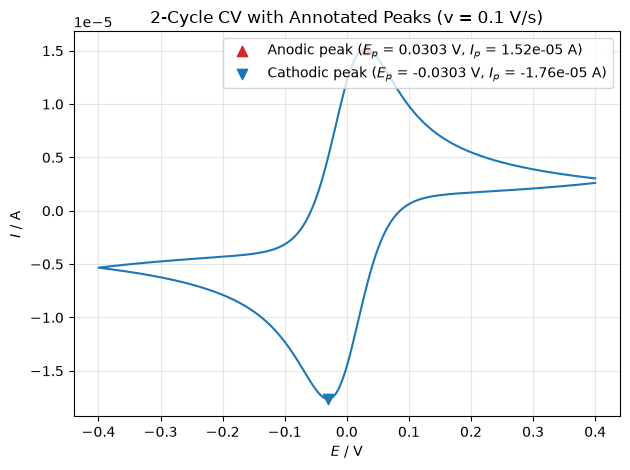

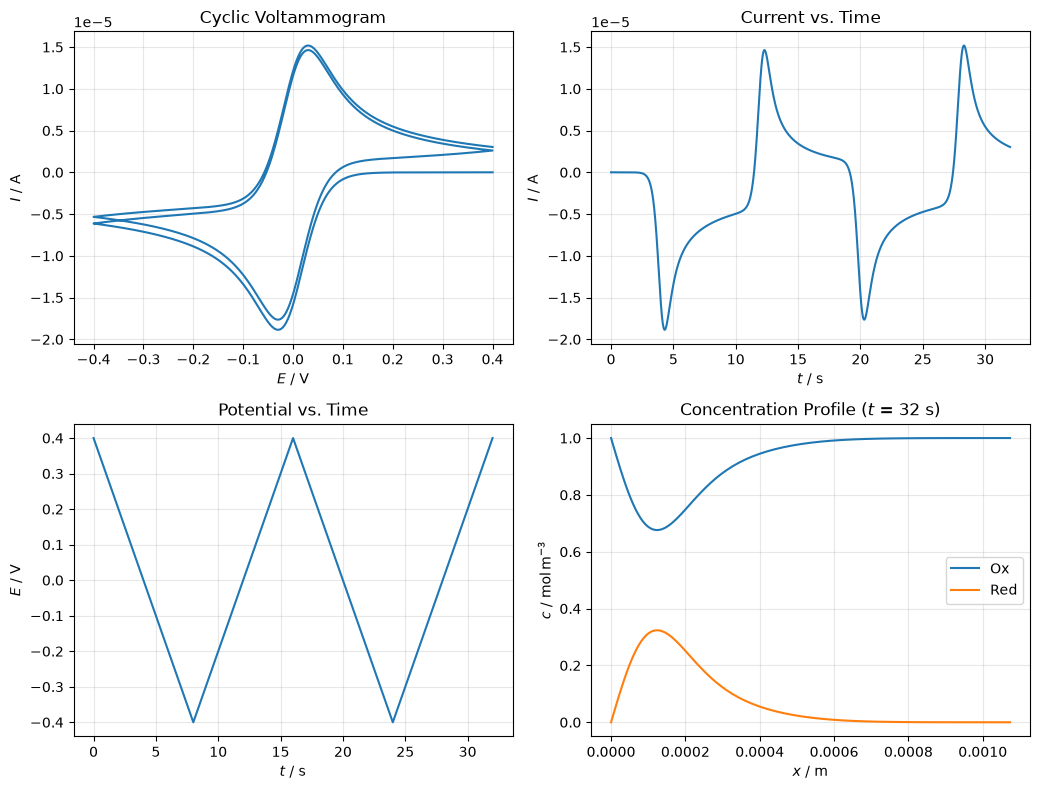

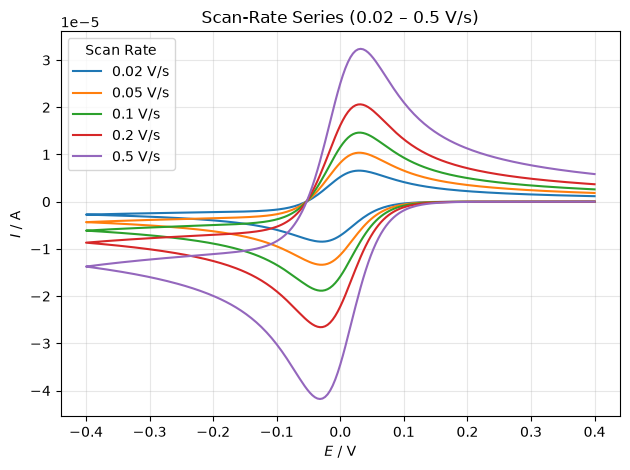

In [3]:
peaks = find_peaks(cv_result)
print(f"E_pc = {peaks.cathodic_peak.E_peak:.4f} V, I_pc = {peaks.cathodic_peak.I_peak * 1e6:.2f} uA")
print(f"E_pa = {peaks.anodic_peak.E_peak:.4f} V, I_pa = {peaks.anodic_peak.I_peak * 1e6:.2f} uA")
print(f"delta_Ep = {peaks.delta_Ep * 1e3:.1f} mV, E_half = {peaks.E_half:.4f} V")

fig, ax = plot_peaks(cv_result)
ax.set_title("2-Cycle CV with Annotated Peaks (v = 0.1 V/s)")
plt.tight_layout()
plt.show()

fig_sum, _ = plot_summary(cv_result)
plt.show()

fig_swp, ax_swp = plot_sweep(
    sweep_results,
    labels=[f"{v} V/s" for v in scan_rates],
    legend_title="Scan Rate",
)
ax_swp.set_title("Scan-Rate Series (0.02 – 0.5 V/s)")
plt.tight_layout()
plt.show()

## 5. Key Takeaways

- `CyclicVoltammetry(..., n_cycles=2)` handles piecewise switching events automatically.
- `find_peaks()` refines peak potentials parabolically and reports $\Delta E_p$, $E_{1/2}$, and $|I_{pa}/I_{pc}|$.
- `simulate_sweep()` + `plot_sweep()` make multi-scan-rate studies one-liners.
- **Next**: Explore [Randles–Ševčík Analysis](../mechanisms/cv_randles_sevcik.ipynb) or [Butler–Volmer Kinetics](../mechanisms/cv_butler_volmer.ipynb).